## ***Why do bank customers leave?***
## A statistical analysis of customer churn in a European retail bank

**RM402E Statistics & Data Analysis, Rennes School of Business, Group Project 2026**

- **Team members** Aya ITTAS, Mohamed Amine DOUAH, Givi KVARATSKHELIYA, Eva BAGAEVA, Yashwanth Chamanahalli NAGESH, Darryl Krystale MEHOHI

- **GitHub repository** https://github.com/ayaittas/Bank-churn-analysis

- **Dataset** [Churn Modelling on Kaggle](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling), file `Churn_Modelling.csv` (10,000 customers, 14 columns)

## 1. The problem

When a customer closes their account, the bank loses the deposits and all the future revenue of this customer. If the bank can understand who leaves, and spot these customers early, it can try to keep them with a call, an offer or a better service.

Our dataset describes 10,000 customers of a retail bank that operates in France, Germany and Spain. Each row is one customer. The column `Exited` tells us if the customer left the bank (1) or stayed (0). In the rest of the notebook we call the customers who left "leavers" and the others "stayers", and we call the share of leavers the "churn rate".

We chose this dataset because it comes from the catalogue of financial datasets of the course, it was not used in class, and it mixes numerical and categorical variables, so we can apply most of the techniques of the course to it.

We want to answer three questions.

1. Who are the customers who leave? We use descriptive statistics, charts and probabilities (sections 3 to 5).
2. Are the differences between leavers and stayers real, or could they be due to chance? We use confidence intervals and hypothesis tests (sections 6 and 7).
3. Can we predict which customers will leave? We use logistic regression and random forest (section 8).

| Variable | Meaning |
|---|---|
| `RowNumber`, `CustomerId`, `Surname` | identifiers of the customer |
| `CreditScore` | credit score of the customer, between 350 and 850 |
| `Geography` | country of the customer (France, Germany or Spain) |
| `Gender` | Female or Male |
| `Age` | age in years |
| `Tenure` | number of years the person has been a customer |
| `Balance` | money on the account |
| `NumOfProducts` | number of products of the bank the customer uses (1 to 4) |
| `HasCrCard` | 1 if the customer has a credit card |
| `IsActiveMember` | 1 if the customer is an active member |
| `EstimatedSalary` | estimated yearly salary |
| `Exited` | **target**, 1 if the customer left the bank |

In [ ]:
# Libraries used in the project
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sn
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import classification_report

# Same look for all the charts of the notebook
COLOR_STAYED = "#2a78d6"   # blue for the customers who stayed
COLOR_LEFT = "#eb6834"     # orange for the customers who left
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

In [ ]:
# In Google Colab, run the two lines below first to upload Churn_Modelling.csv
# from google.colab import files
# uploaded = files.upload()

# Read the dataset
df = pd.read_csv("Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
# Size of the dataset (rows, columns)
df.shape

(10000, 14)

In [ ]:
# Type of each column and number of non missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


We have 10,000 rows and 14 columns. Eleven columns are numbers and three are text (`Surname`, `Geography`, `Gender`). Three of the numerical columns (`HasCrCard`, `IsActiveMember`, `Exited`) are in fact yes/no variables coded 1 and 0.

## 2. Data cleaning

Before any analysis we check the quality of the data. We look for missing values, duplicated customers, columns that are useless for the analysis and values that are not plausible.

In [ ]:
# Missing values in each column
df.isna().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [ ]:
# Duplicated rows and duplicated customer identifiers
print("Duplicated rows =", df.duplicated().sum())
print("Duplicated customer ids =", df["CustomerId"].duplicated().sum())

Duplicated rows = 0
Duplicated customer ids = 0


In [ ]:
# RowNumber, CustomerId and Surname only identify the customer.
# They say nothing about behaviour, so we remove them.
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

# A readable label that we will use in the charts and tables
df["Status"] = df["Exited"].map({0: "Stayed", 1: "Left"})
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Status
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Left
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Stayed
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Left
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Stayed
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Stayed


In [ ]:
# Check the categories of the two text columns
print(df["Geography"].unique())
print(df["Gender"].unique())

<StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str
<StringArray>
['Female', 'Male']
Length: 2, dtype: str


In [ ]:
# Check that the minimum and the maximum of each numerical column are plausible
df.describe().loc[["min", "max"]]

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
min,350.0,18.0,0.0,0.00,1.0,0.0,0.0,11.58,0.0
max,850.0,92.0,10.0,250898.09,4.0,1.0,1.0,199992.48,1.0


**What we found**

- There is no missing value and no duplicated customer, so we do not have to fill or delete any row.
- We removed the three identifier columns. We keep 10 explanatory variables and the target `Exited`.
- The text columns are clean. There are exactly three countries and two genders, with no spelling variants.
- The ranges are plausible. Customers are between 18 and 92 years old, the credit score goes from 350 to 850 and the tenure from 0 to 10 years.
- Two things look unusual but we keep them. The minimum balance is 0, which simply means an empty account (we come back to it in section 4). The minimum estimated salary is 11.58, which is very low for a yearly salary, but we cannot know if it is an error and deleting it would be arbitrary.

## 3. Descriptive statistics

We start with the usual measures of central tendency and dispersion, first for all customers and then separately for stayers and leavers.

In [ ]:
# Main descriptive statistics of the numerical variables
df.describe().round(2)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


In [ ]:
# Skewness of the continuous variables (0 means a symmetric distribution)
df[["CreditScore", "Age", "Balance", "EstimatedSalary"]].skew().round(2)

CreditScore       -0.07
Age                1.01
Balance           -0.14
EstimatedSalary    0.00
dtype: float64

- **Age** The mean is 38.92 years and the median is 37. The mean is above the median and the skewness is positive (1.01), so the distribution has a tail on the right. Most customers are young adults and a small number of old customers pull the mean up.
- **Credit score** The mean (650.53) and the median (652) are almost equal and the skewness is close to 0. The distribution is almost symmetric.
- **Balance** The mean is 76,485.89 but the first quartile is 0. At least a quarter of the customers have an empty account, so the mean alone describes this variable badly.
- **Estimated salary** It is spread between almost 0 and 200,000 with a mean of 100,090 and a skewness of 0.00.

In [ ]:
# How many customers left the bank?
print(df["Status"].value_counts())
print("Churn rate =", round(df["Exited"].mean() * 100, 2), "%")

Status
Stayed    7963
Left      2037
Name: count, dtype: int64
Churn rate = 20.37 %


In [ ]:
# Average profile of the customers who stayed and of the customers who left
numeric_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
df.groupby("Status")[numeric_cols].mean().round(2)

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Status,,,,,,
Left,645.35,44.84,4.93,91108.54,1.48,101465.68
Stayed,651.85,37.41,5.03,72745.30,1.54,99738.39


In [ ]:
# Same comparison with the median, which is less sensitive to extreme values
df.groupby("Status")[numeric_cols].median()

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Status,,,,,,
Left,646.0,45.0,5.0,109349.29,1.0,102460.84
Stayed,653.0,36.0,5.0,92072.68,2.0,99645.04


In [ ]:
# Churn rate (in %) inside each category
for col in ["Geography", "Gender", "IsActiveMember", "HasCrCard", "NumOfProducts"]:
    table = df.groupby(col)["Exited"].agg(["count", "mean"])
    table.columns = ["Customers", "Churn rate %"]
    table["Churn rate %"] = (table["Churn rate %"] * 100).round(1)
    print(table)
    print("----------------------------------")

           Customers  Churn rate %
Geography                         
France          5014          16.2
Germany         2509          32.4
Spain           2477          16.7
----------------------------------
        Customers  Churn rate %
Gender                         
Female       4543          25.1
Male         5457          16.5
----------------------------------
                Customers  Churn rate %
IsActiveMember                         
0                    4849          26.9
1                    5151          14.3
----------------------------------
           Customers  Churn rate %
HasCrCard                         
0               2945          20.8
1               7055          20.2
----------------------------------
               Customers  Churn rate %
NumOfProducts                         
1                   5084          27.7
2                   4590           7.6
3                    266          82.7
4                     60         100.0
-----------------------

**First observations**

- 2,037 customers out of 10,000 left the bank. The churn rate is 20.37%, so about one customer in five.
- Leavers are clearly older. Their mean age is 44.84 years against 37.41 for stayers (medians 45 and 36).
- Leavers have more money on their account, with a mean balance of 91,109 against 72,745.
- The credit score, the tenure and the salary are almost the same in the two groups.
- The churn rate is twice as high in Germany (32.4%) as in France (16.2%) and Spain (16.7%).
- Women leave more often than men (25.1% against 16.5%) and inactive members more often than active members (26.9% against 14.3%).
- Having a credit card changes almost nothing (20.2% against 20.8%).
- The number of products gives the most surprising result. Customers with 2 products rarely leave (7.6%), customers with 1 product leave more (27.7%), and almost all the customers with 3 or 4 products leave (82.7% and 100%). These last two groups are small (266 and 60 customers).

These are only observations on our data. In sections 6 and 7 we check if they are statistically significant.

## 4. Exploratory data analysis

We now look at the same information with charts. In all the charts blue is used for stayers and orange for leavers.

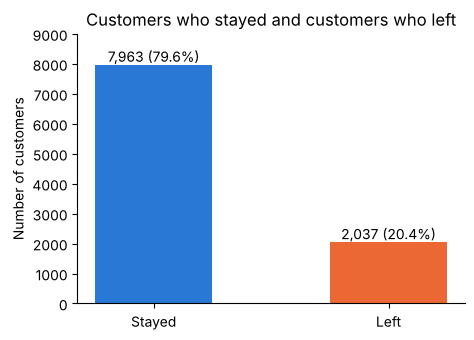

In [ ]:
# Number of customers who stayed and who left
counts = df["Status"].value_counts().reindex(["Stayed", "Left"])

plt.figure(figsize=(5, 3.5))
bars = plt.bar(counts.index, counts.values, color=[COLOR_STAYED, COLOR_LEFT], width=0.5)
plt.bar_label(bars, labels=[f"{v:,} ({v / len(df):.1%})" for v in counts.values])
plt.title("Customers who stayed and customers who left")
plt.ylabel("Number of customers")
plt.ylim(0, 9000)
plt.show()

The two groups do not have the same size. There are about four stayers for one leaver. We will have to remember this in section 8, because a model can reach a high accuracy just by predicting that everybody stays.

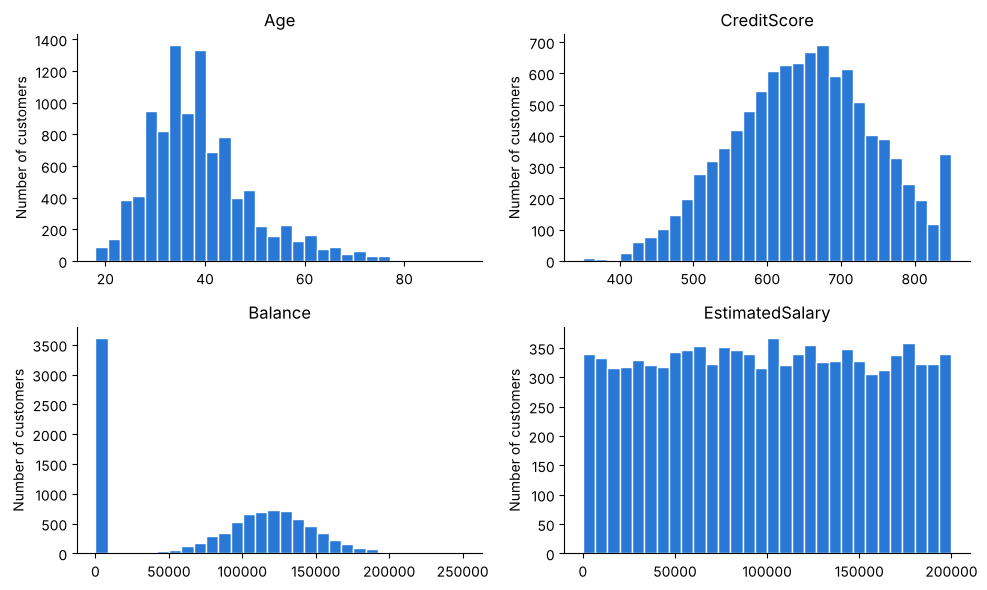

In [ ]:
# Distribution of the four continuous variables
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.flatten(), ["Age", "CreditScore", "Balance", "EstimatedSalary"]):
    ax.hist(df[col], bins=30, color=COLOR_STAYED, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Number of customers")
    ax.locator_params(axis="x", nbins=6)   # fewer labels on the x axis so they stay readable
plt.tight_layout()
plt.show()

In [ ]:
# How many customers have an empty account, and how many have the maximum credit score?
print("Customers with a balance of 0 =", (df["Balance"] == 0).sum())
print("Median balance of the customers who have money on their account =", round(df[df["Balance"] > 0]["Balance"].median(), 2))
print("Customers with the maximum credit score of 850 =", (df["CreditScore"] == 850).sum())

Customers with a balance of 0 = 3617
Median balance of the customers who have money on their account = 119839.69
Customers with the maximum credit score of 850 = 233


- **Age** is skewed to the right, with most customers between 30 and 40.
- **CreditScore** has a bell shape, but with a peak on the last bar because 233 customers have the maximum score of 850.
- **Balance** is made of two populations. 3,617 customers (36.2%) have exactly 0 on their account, and the others are spread in a bell shape around 120,000.
- **EstimatedSalary** is flat. All salary levels are about equally frequent, which is very different from a normal distribution.

None of these variables looks like a clean normal distribution. We test this formally in section 5.

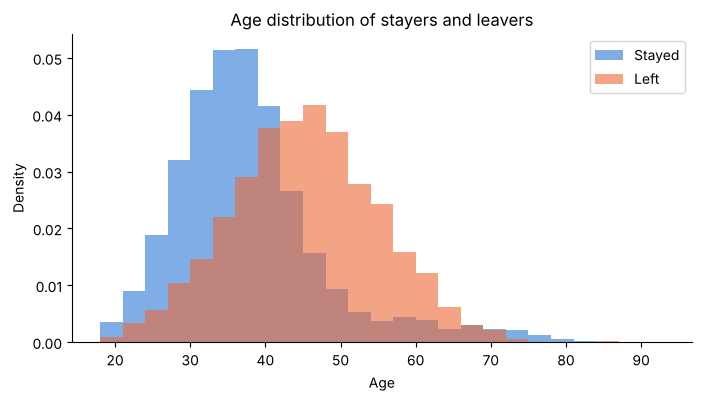

In [ ]:
# Age of the customers who stayed compared with the customers who left.
# density=True puts both groups on the same scale even if their sizes are different.
bins = range(18, 96, 3)
plt.figure(figsize=(8, 4))
plt.hist(df[df["Exited"] == 0]["Age"], bins=bins, density=True, alpha=0.6, color=COLOR_STAYED, label="Stayed")
plt.hist(df[df["Exited"] == 1]["Age"], bins=bins, density=True, alpha=0.6, color=COLOR_LEFT, label="Left")
plt.title("Age distribution of stayers and leavers")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.show()

The two distributions are clearly shifted. Stayers are concentrated between 30 and 40 years, while leavers are concentrated between 40 and 50. Age looks like the variable that separates the two groups best.

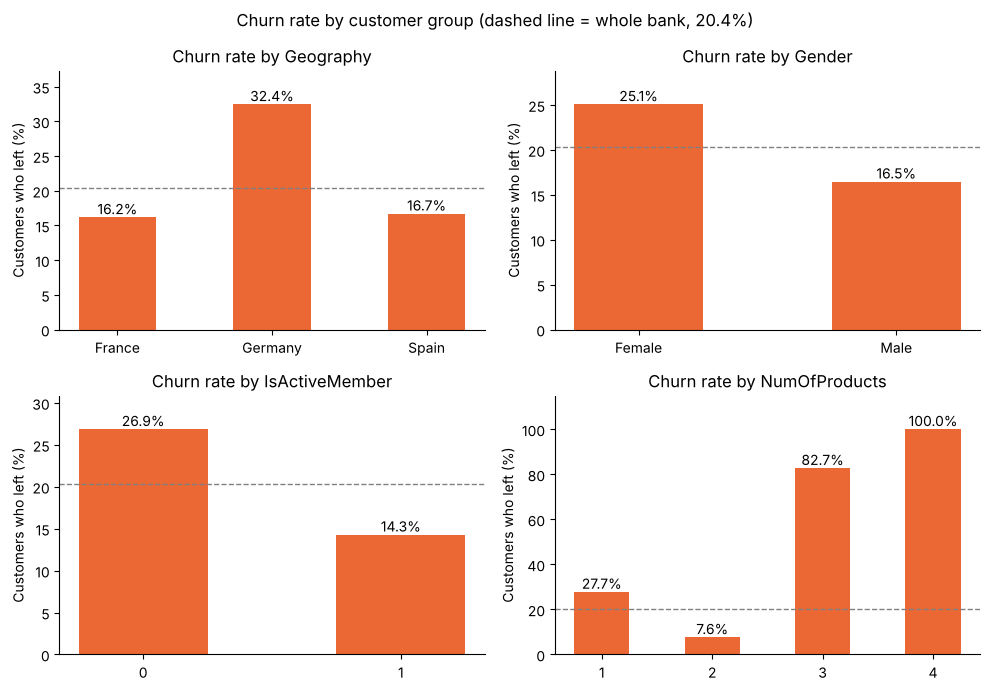

In [ ]:
# Churn rate inside each customer group.
# The dashed line is the churn rate of the whole bank.
overall_rate = df["Exited"].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flatten(), ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]):
    rate = df.groupby(col)["Exited"].mean() * 100
    bars = ax.bar(rate.index.astype(str), rate.values, color=COLOR_LEFT, width=0.5)
    ax.bar_label(bars, fmt="%.1f%%")
    ax.set_ylim(0, rate.max() * 1.15)   # a little room above the labels
    ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1)
    ax.set_title("Churn rate by " + col)
    ax.set_ylabel("Customers who left (%)")
fig.suptitle(f"Churn rate by customer group (dashed line = whole bank, {overall_rate:.1f}%)")
plt.tight_layout()
plt.show()

The dashed line helps to see which groups are above or below the average of the bank. German customers, women, inactive members and customers with 3 or 4 products are above it. The chart of the number of products shows that the relation is not a straight line. The churn rate goes down from 1 to 2 products and then goes up very strongly.

## 5. Probability and distributions

### 5.1 Are our variables normally distributed?

In class we saw that we can only use the normal distribution to compute probabilities if the variable is normal. We check it with the Shapiro-Wilk test.

- H0 says that the variable follows a normal distribution.
- H1 says that it does not.
- If the p_value is below 0.05 we reject H0.

In [ ]:
# Shapiro-Wilk normality test.
# The test is designed for small samples, so we apply it to a random sample of 1,000 customers.
sample = df.sample(1000, random_state=0)
for col in ["Age", "CreditScore", "Balance", "EstimatedSalary"]:
    statistic, p_value = stats.shapiro(sample[col])
    print(col, "  W =", round(statistic, 4), "  p_value =", p_value)

Age   W = 0.935   p_value = 1.8310487878462668e-20
CreditScore   W = 0.9927   p_value = 7.707572000501206e-05
Balance   W = 0.8488   p_value = 7.685660968523211e-30
EstimatedSalary   W = 0.9556   p_value = 7.675400321523384e-17


All the p_values are far below 0.05, so we reject H0 for the four variables. None of them is normal, which confirms what we saw on the histograms. As in class, we stop here for the normal distribution and we do not use `norm.cdf` on these variables. We compute the probabilities directly from the observed frequencies instead.

### 5.2 Probabilities from observed frequencies

In [ ]:
# Probabilities computed directly from the 10,000 customers
print("P(Age > 60) =", round((df["Age"] > 60).mean(), 4))
print("P(30 <= Age <= 40) =", round(df["Age"].between(30, 40).mean(), 4))
print("20th percentile of age =", df["Age"].quantile(0.20))
print("90th percentile of age =", df["Age"].quantile(0.90))

P(Age > 60) = 0.0464
P(30 <= Age <= 40) = 0.4778
20th percentile of age = 31.0
90th percentile of age = 53.0


In [ ]:
# Conditional probabilities of leaving the bank
p_left = df["Exited"].mean()
p_left_over_50 = df[df["Age"] > 50]["Exited"].mean()
p_left_under_30 = df[df["Age"] < 30]["Exited"].mean()
p_left_german_inactive = df[(df["Geography"] == "Germany") & (df["IsActiveMember"] == 0)]["Exited"].mean()

print("P(Left) =", round(p_left, 4))
print("P(Left | Age > 50) =", round(p_left_over_50, 4))
print("P(Left | Age < 30) =", round(p_left_under_30, 4))
print("P(Left | German and inactive) =", round(p_left_german_inactive, 4))

P(Left) = 0.2037
P(Left | Age > 50) = 0.4465
P(Left | Age < 30) = 0.0756
P(Left | German and inactive) = 0.4108


- Only 4.64% of the customers are older than 60, and almost half of them (47.78%) are between 30 and 40.
- The youngest 20% of the customers are at most 31 years old and the oldest 10% are at least 53.
- If we pick a customer at random, the probability that this customer left is 20.37%. If we know that the customer is older than 50, it becomes 44.65%, more than twice as high. If the customer is younger than 30, it falls to 7.56%.
- For an inactive German customer the probability is 41.08%.

The probability of leaving changes a lot when we know the profile of the customer. In the language of probability, leaving and the profile are not independent events. This is exactly what makes prediction possible in section 8.

### 5.3 Central Limit Theorem

Age is not normal. The Central Limit Theorem says that the mean of a large enough sample is approximately normal anyway. We check it with a simulation.

In [ ]:
# We draw 1,000 random samples of 100 customers and we keep the mean age of each sample
np.random.seed(0)
sample_means = []
for i in range(1000):
    one_sample = np.random.choice(df["Age"], size=100)
    sample_means.append(one_sample.mean())
sample_means = np.array(sample_means)

print("Mean age of all customers =", round(df["Age"].mean(), 2))
print("Mean of the 1,000 sample means =", round(sample_means.mean(), 2))
print("Standard deviation of the sample means =", round(sample_means.std(), 3))
print("Theoretical standard error (sigma / sqrt(n)) =", round(df["Age"].std() / np.sqrt(100), 3))
print("Shapiro p_value for the sample means =", round(stats.shapiro(sample_means)[1], 4))

Mean age of all customers = 38.92
Mean of the 1,000 sample means = 38.91
Standard deviation of the sample means = 1.05
Theoretical standard error (sigma / sqrt(n)) = 1.049
Shapiro p_value for the sample means = 0.3544


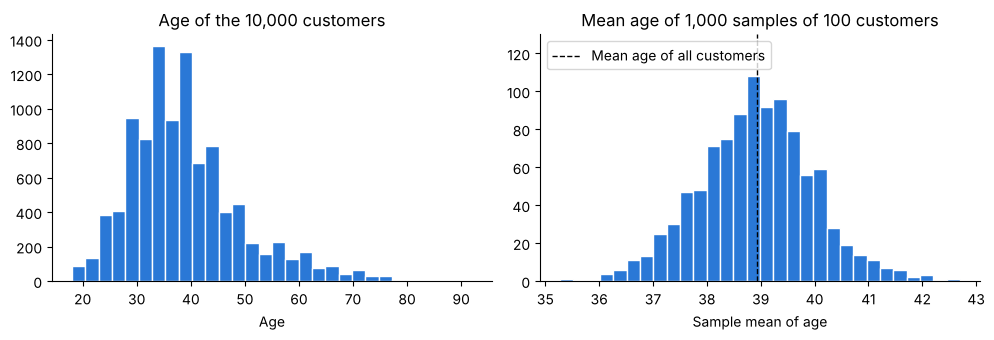

In [ ]:
# Age of individual customers (left) compared with the mean age of the samples (right)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["Age"], bins=30, color=COLOR_STAYED, edgecolor="white")
axes[0].set_title("Age of the 10,000 customers")
axes[0].set_xlabel("Age")
axes[1].hist(sample_means, bins=30, color=COLOR_STAYED, edgecolor="white")
axes[1].axvline(df["Age"].mean(), color="black", linestyle="--", linewidth=1, label="Mean age of all customers")
axes[1].set_title("Mean age of 1,000 samples of 100 customers")
axes[1].set_xlabel("Sample mean of age")
axes[1].set_ylim(0, 130)   # room for the legend above the bars
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
# The sample means are normal, so this time we can use the normal distribution.
# Probability that a random group of 100 customers has a mean age above 41.
mu = df["Age"].mean()
standard_error = df["Age"].std() / np.sqrt(100)

print("With the normal distribution =", round(1 - stats.norm.cdf(41, loc=mu, scale=standard_error), 4))
print("Observed in our 1,000 samples =", round((sample_means > 41).mean(), 4))

With the normal distribution = 0.0238
Observed in our 1,000 samples = 0.028


The simulation matches the theory.

- The sample means are centred on the true mean (38.91 against 38.92).
- Their standard deviation (1.050) is equal to the theoretical standard error sigma / sqrt(n) = 1.049.
- The Shapiro test gives a p_value of 0.3544, above 0.05, so we do not reject normality for the sample means. The histogram on the right is symmetric while the histogram of individual ages on the left is skewed.

Because the sample means are normal, we can use the normal distribution for them. The normal distribution gives a probability of 2.38% that a group of 100 customers has a mean age above 41, and we observe 2.8% in our simulation (28 samples out of 1,000), which is close.

This result matters for the rest of the project. It is the reason why we can build confidence intervals for a mean (section 6) even if the variable itself is not normal.

## 6. Confidence intervals

Our 10,000 customers are only a sample of all the customers of the bank. A confidence interval gives the range in which the true value is likely to be, with a confidence level of 95%.

In [ ]:
# 95% confidence interval for the mean age of each group (Student t interval)
for label in ["Stayed", "Left"]:
    x = df[df["Status"] == label]["Age"]
    low, high = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
    print(label, " n =", len(x), " mean age =", round(x.mean(), 2),
          " 95% CI = [", round(low, 2), ",", round(high, 2), "]")

Stayed  n = 7963  mean age = 37.41  95% CI = [ 37.19 , 37.63 ]
Left  n = 2037  mean age = 44.84  95% CI = [ 44.41 , 45.26 ]


In [ ]:
# 95% confidence interval for the churn rate (a proportion) of the bank and of each country
# margin of error = z * sqrt(p * (1 - p) / n), with z = 1.96 for 95%
z = stats.norm.ppf(0.975)

rows = []
groups = {"Whole bank": df, "France": df[df["Geography"] == "France"],
          "Germany": df[df["Geography"] == "Germany"], "Spain": df[df["Geography"] == "Spain"]}
for name, group in groups.items():
    n = len(group)
    p = group["Exited"].mean()
    margin = z * np.sqrt(p * (1 - p) / n)
    rows.append([name, n, p * 100, margin * 100, (p - margin) * 100, (p + margin) * 100])

ci_table = pd.DataFrame(rows, columns=["Group", "Customers", "Churn rate %", "Margin %", "CI low %", "CI high %"])
ci_table.round(2)

,Group,Customers,Churn rate %,Margin %,CI low %,CI high %
0,Whole bank,10000,20.37,0.79,19.58,21.16
1,France,5014,16.15,1.02,15.14,17.17
2,Germany,2509,32.44,1.83,30.61,34.28
3,Spain,2477,16.67,1.47,15.21,18.14


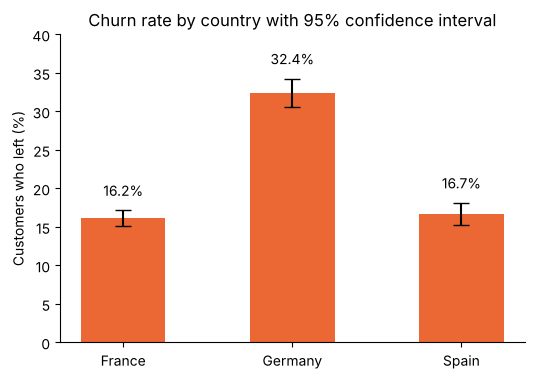

In [ ]:
# Churn rate by country with its 95% confidence interval
countries = ci_table[ci_table["Group"] != "Whole bank"]

plt.figure(figsize=(6, 4))
bars = plt.bar(countries["Group"], countries["Churn rate %"], yerr=countries["Margin %"],
               capsize=6, color=COLOR_LEFT, width=0.5)
plt.bar_label(bars, fmt="%.1f%%", padding=8)
plt.title("Churn rate by country with 95% confidence interval")
plt.ylabel("Customers who left (%)")
plt.ylim(0, 40)
plt.show()

- **Mean age** We are 95% confident that the mean age of stayers is between 37.19 and 37.63 years, and that the mean age of leavers is between 44.41 and 45.26 years. The two intervals are narrow and very far from each other, so the age difference of about 7.4 years is not due to chance.
- **Churn rate of the bank** It is 20.37% with a margin of error of 0.79 points, so between 19.58% and 21.16%.
- **Churn rate by country** The interval of Germany (30.61% to 34.28%) is far above the intervals of France (15.14% to 17.17%) and Spain (15.21% to 18.14%). The intervals of France and Spain overlap, so we cannot say that these two countries are different. The interval of Spain is wider than the interval of France because there are fewer Spanish customers (2,477 against 5,014).

## 7. Hypothesis testing

We now test formally what we observed. To choose each test we follow the decision tree of the course "Choosing the right statistical test". For every test we use a significance level of 5%. If the p_value is below 0.05 we reject H0.

| Situation | Normal data | Not normal data |
|---|---|---|
| 2 independent groups | Independent t-test | Mann-Whitney U test |
| 3 or more independent groups | One-way ANOVA | Kruskal-Wallis test |
| 2 numerical variables | Pearson correlation | Spearman correlation |
| 2 categorical variables | Chi-square test | Chi-square test |

### 7.1 Do leavers and stayers have different profiles? (2 independent groups)

- H0 says that the variable has the same distribution for leavers and stayers.
- H1 says that the distribution is different.

The two groups are independent because a customer cannot be in both. We first check normality in each group.

In [ ]:
# The two groups we want to compare
stayed = df[df["Exited"] == 0]
left = df[df["Exited"] == 1]

# Step 1. Normality of each group (Shapiro-Wilk on a random sample of 1,000 customers per group)
test_cols = ["Age", "Balance", "CreditScore", "Tenure", "EstimatedSalary"]
for col in test_cols:
    p_stayed = stats.shapiro(stayed[col].sample(1000, random_state=0))[1]
    p_left = stats.shapiro(left[col].sample(1000, random_state=0))[1]
    print(col, "  p_value stayed =", p_stayed, "  p_value left =", p_left)

Age   p_value stayed = 2.8167573974845655e-25   p_value left = 0.050875758368604224
Balance   p_value stayed = 5.416394435445835e-31   p_value left = 4.030360655447754e-28
CreditScore   p_value stayed = 0.00014436192843940735   p_value left = 0.0006875155341984537
Tenure   p_value stayed = 1.7325167012259406e-18   p_value left = 2.202222349155412e-18
EstimatedSalary   p_value stayed = 2.5167016278430472e-14   p_value left = 1.9946040839276667e-17


For every variable at least one of the two groups is not normal. The only p_value above 0.05 is the age of leavers (0.051), and it is just at the limit, while the age of stayers is clearly not normal. The condition of the t-test is not met, so we use the Mann-Whitney U test.

In [ ]:
# Step 2. The groups are independent and not normal, so we use the Mann-Whitney U test
rows = []
for col in test_cols:
    statistic, p_value = stats.mannwhitneyu(left[col], stayed[col])
    if p_value < 0.05:
        decision = "Reject H0"
    else:
        decision = "Do not reject H0"
    rows.append([col, stayed[col].median(), left[col].median(), p_value, decision])

mw_table = pd.DataFrame(rows, columns=["Variable", "Median stayed", "Median left", "p_value", "Decision (5%)"])
mw_table

,Variable,Median stayed,Median left,p_value,Decision (5%)
0,Age,36.00,45.00,3.210401e-230,Reject H0
1,Balance,92072.68,109349.29,1.115840e-28,Reject H0
2,CreditScore,653.00,646.00,1.986866e-02,Reject H0
3,Tenure,5.00,5.00,1.621938e-01,Do not reject H0
4,EstimatedSalary,99645.04,102460.84,2.270515e-01,Do not reject H0


In [ ]:
# Check with a t-test for Age. With thousands of customers per group the Central Limit Theorem
# makes the t-test reliable even if the data are not normal (equal_var=False = Welch version).
statistic, p_value = stats.ttest_ind(left["Age"], stayed["Age"], equal_var=False)
print("t statistic =", round(statistic, 2), "  p_value =", p_value)

t statistic = 30.42   p_value = 4.7127272656634046e-179


- **Age and Balance** The p_values are practically 0. We reject H0. Leavers are older and have higher balances than stayers, and this is not due to chance. The t-test on age gives the same conclusion as the Mann-Whitney test.
- **CreditScore** The p_value is 0.0199, so we also reject H0 at 5%. But the difference is very small (median of 646 against 653). With 10,000 customers even a small difference becomes statistically significant. It is significant but not very useful in practice.
- **Tenure and EstimatedSalary** The p_values are 0.162 and 0.227, above 0.05. We do not reject H0. We have no evidence that leavers and stayers differ on seniority or salary.

### 7.2 Is churn linked to the categorical variables? (Chi-square test)

- H0 says that churn is independent of the variable.
- H1 says that churn depends on the variable.

We first show the test in detail for the country, then we run it for all the categorical variables.

In [ ]:
# Chi-square test of independence. Example with the country.
observed = pd.crosstab(df["Geography"], df["Status"])
chi2, p_value, dof, expected = stats.chi2_contingency(observed)

print("Observed numbers of customers")
print(observed)
print()
print("Numbers expected if churn did not depend on the country")
print(pd.DataFrame(expected, index=observed.index, columns=observed.columns).round(1))
print()
print("chi2 =", round(chi2, 2), "  degrees of freedom =", dof, "  p_value =", p_value)

Observed numbers of customers
Status     Left  Stayed
Geography              
France      810    4204
Germany     814    1695
Spain       413    2064

Numbers expected if churn did not depend on the country
Status       Left  Stayed
Geography                
France     1021.4  3992.6
Germany     511.1  1997.9
Spain       504.6  1972.4

chi2 = 301.26   degrees of freedom = 2   p_value = 3.8303176053541544e-66


In [ ]:
# Same test for all the categorical variables
rows = []
for col in ["Geography", "Gender", "IsActiveMember", "NumOfProducts", "HasCrCard"]:
    observed = pd.crosstab(df[col], df["Exited"])
    chi2, p_value, dof, expected = stats.chi2_contingency(observed)
    if p_value < 0.05:
        decision = "Reject H0"
    else:
        decision = "Do not reject H0"
    rows.append([col, round(chi2, 2), dof, p_value, decision])

chi2_table = pd.DataFrame(rows, columns=["Variable", "chi2", "dof", "p_value", "Decision (5%)"])
chi2_table

,Variable,chi2,dof,p_value,Decision (5%)
0,Geography,301.26,2,3.830318e-66,Reject H0
1,Gender,112.92,1,2.248210e-26,Reject H0
2,IsActiveMember,242.99,1,8.785858e-55,Reject H0
3,NumOfProducts,1503.63,3,0.000000e+00,Reject H0
4,HasCrCard,0.47,1,4.923724e-01,Do not reject H0


- **Geography** If churn did not depend on the country we would expect about 511 leavers in Germany. We observe 814. The p_value is practically 0, so we reject H0. Churn depends on the country.
- **Gender, IsActiveMember, NumOfProducts** We reject H0 for the three variables. The number of products has by far the largest chi2 (1,503.63). Its p_value is displayed as 0 because it is too small for Python to show.
- **HasCrCard** The p_value is 0.49. We do not reject H0. Having a credit card has no link with churn, so a retention plan based on credit cards would probably be useless.

### 7.3 Is the balance the same in the three countries? (3 independent groups)

We saw that leavers have higher balances and that German customers leave more. We want to know if these two facts are connected.

- H0 says that the balance has the same distribution in the three countries.
- H1 says that at least one country is different.

In [ ]:
# Balance in the three countries
print(df.groupby("Geography")["Balance"].agg(["mean", "median"]).round(0))
print()
print("Share of customers with a balance of zero (%)")
print((df["Balance"] == 0).groupby(df["Geography"]).mean().mul(100).round(1))

               mean    median
Geography                    
France      62093.0   62154.0
Germany    119730.0  119703.0
Spain       61818.0   61710.0

Share of customers with a balance of zero (%)
Geography
France     48.2
Germany     0.0
Spain      48.4
Name: Balance, dtype: float64


In [ ]:
# Three independent groups that are not normal, so we use the Kruskal-Wallis test
france = df[df["Geography"] == "France"]["Balance"]
germany = df[df["Geography"] == "Germany"]["Balance"]
spain = df[df["Geography"] == "Spain"]["Balance"]

statistic, p_value = stats.kruskal(france, germany, spain)
print("Kruskal-Wallis H =", round(statistic, 2), "  p_value =", p_value)

Kruskal-Wallis H = 1381.93   p_value = 8.255739707922365e-301


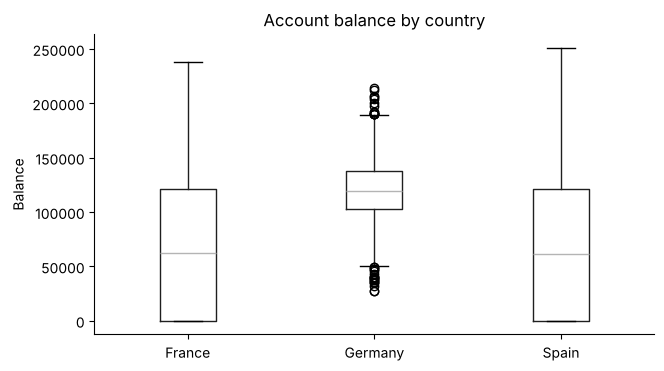

In [ ]:
# Boxplot of the balance by country
df.boxplot(column="Balance", by="Geography", figsize=(7, 4), grid=False)
plt.suptitle("")
plt.title("Account balance by country")
plt.xlabel("")
plt.ylabel("Balance")
plt.show()

The p_value is practically 0, so we reject H0. The balance is not the same in the three countries. The table explains why. Almost half of the French and Spanish customers have an empty account (48.2% and 48.4%), while no German customer has one. The mean balance in Germany (119,730) is almost twice the mean in France and Spain (about 62,000).

This is an important finding. Country and balance are linked to each other, so when we see that leavers have higher balances, a part of this effect may simply come from the fact that German customers leave more. To separate the two effects we need a model that looks at all the variables at the same time. This is what we do in section 8.

### 7.4 Correlation analysis

Our variables are not normal, so we use Spearman's correlation and not Pearson's.

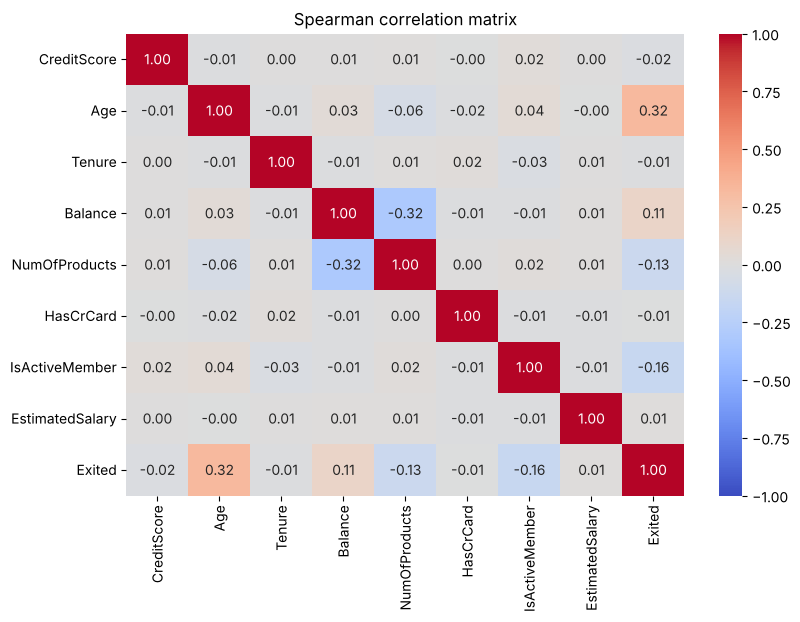

In [ ]:
# Spearman correlation matrix
corr_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
             "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]
corr = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(9, 6))
sn.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation matrix")
plt.show()

In [ ]:
# Correlation of each variable with the target, from the most positive to the most negative
print(corr["Exited"].drop("Exited").sort_values(ascending=False).round(3))

Age                0.324
Balance            0.111
EstimatedSalary    0.012
HasCrCard         -0.007
Tenure            -0.014
CreditScore       -0.023
NumOfProducts     -0.125
IsActiveMember    -0.156
Name: Exited, dtype: float64


In [ ]:
# Significance test for the three strongest correlations of the matrix
for a, b in [("Age", "Exited"), ("Balance", "NumOfProducts"), ("IsActiveMember", "Exited")]:
    rho, p_value = stats.spearmanr(df[a], df[b])
    print(a, "and", b, "  rho =", round(rho, 3), "  p_value =", p_value)

Age and Exited   rho = 0.324   p_value = 4.6036797504146504e-243
Balance and NumOfProducts   rho = -0.317   p_value = 1.1231942719451212e-231
IsActiveMember and Exited   rho = -0.156   p_value = 1.3482685164858117e-55


- Age has the strongest correlation with churn (0.324). It is positive, so the older the customer the more likely they are to leave. It is a moderate correlation, so age alone does not explain everything.
- Being an active member (-0.156) and the number of products (-0.125) are negatively correlated with churn. The balance is positively correlated (0.111).
- Credit score, tenure, credit card and salary have correlations close to 0 with churn.
- Between explanatory variables, the only notable correlation is between the balance and the number of products (-0.317). Customers with more products tend to have less money on their account. All the other correlations are close to 0, so the explanatory variables do not repeat the same information. This is good for the regression of section 8.
- The three correlations we tested have p_values that are practically 0, so they are statistically significant.

A correlation only measures relations that always go in the same direction. For the number of products, we saw that the churn rate goes down and then up, so the coefficient of -0.125 hides a much stronger relation.

**Summary of the tests** Age, balance, country, gender, activity and number of products are significantly linked to churn. Tenure, salary and credit card are not. The credit score is significant but its effect is very small.

## 8. Predicting churn

The target `Exited` takes only two values, 0 or 1. A linear regression is not adapted to this kind of target because it could predict values below 0 or above 1. We use the two classification models of the course, logistic regression and random forest.

### 8.1 Preparing the data

In [ ]:
# Explanatory variables and target
X = df[["CreditScore", "Geography", "Gender", "Age", "Tenure", "Balance",
        "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]]
y = df["Exited"]

# Geography and Gender are text, so we convert them into 0/1 columns (dummy variables).
# drop_first=True removes one category per variable (France and Female become the reference).
X = pd.get_dummies(X, columns=["Geography", "Gender"], drop_first=True, dtype=int)
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


In [ ]:
# Split the data. 75% to train the models and 25% to test them on customers they have never seen.
# stratify=y keeps the same share of leavers in both parts.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

print("Training customers =", len(X_train), "  churn rate =", round(y_train.mean() * 100, 2), "%")
print("Testing customers =", len(X_test), "  churn rate =", round(y_test.mean() * 100, 2), "%")

Training customers = 7500   churn rate = 20.37 %
Testing customers = 2500   churn rate = 20.36 %


In [ ]:
# Put all the variables on the same scale (mean 0, standard deviation 1).
# The scaler is fitted on the training data only, so the test data stay unseen.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# A naive model that says "nobody leaves" is our reference point
print("Accuracy of the naive model =", round(1 - y_test.mean(), 4))

Accuracy of the naive model = 0.7964


We keep all the variables, including those that were not significant in section 7, and we let the models show which ones matter.

The variables have very different scales (the balance goes up to 250,000 while the tenure stops at 10), so we standardise them for the logistic regression. This also makes its coefficients comparable.

Because only 20% of the customers leave, a model that always answers "stays" is already right 79.64% of the time while it finds no leaver at all. The accuracy alone is therefore not enough to judge a model. We also look at the scores of the class "Left".

- **Precision** Among the customers the model flags as leavers, how many really leave?
- **Recall** Among the customers who really leave, how many does the model find?
- **F1-score** A single score that combines precision and recall.

For the bank the recall is very important, because a leaver that the model does not find is a customer lost without any attempt to keep them.

In [ ]:
# Function used to evaluate every model in the same way
results = []   # scores of each model, to compare them at the end

def evaluate(name, y_test, y_pred):
    # Confusion matrix (same method as in class)
    confusion_matrix = pd.crosstab(y_test, y_pred, rownames=["Actual"], colnames=["Predicted"])
    plt.figure(figsize=(4, 3))
    sn.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(name)
    plt.show()
    print(confusion_matrix)
    print()
    # Accuracy and detailed report
    print("Accuracy =", round(metrics.accuracy_score(y_test, y_pred), 4))
    print(classification_report(y_test, y_pred, target_names=["Stayed", "Left"]))
    # Keep the scores of the class "Left" for the final comparison
    results.append({
        "Model": name,
        "Accuracy": metrics.accuracy_score(y_test, y_pred),
        "Precision (Left)": metrics.precision_score(y_test, y_pred),
        "Recall (Left)": metrics.recall_score(y_test, y_pred),
        "F1 (Left)": metrics.f1_score(y_test, y_pred),
    })

### 8.2 Model 1. Logistic regression

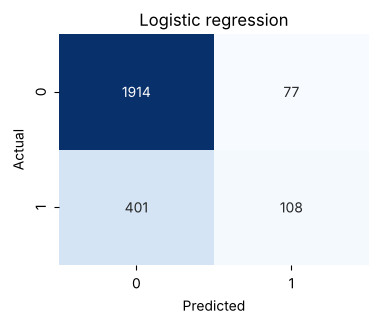

Predicted     0    1
Actual              
0          1914   77
1           401  108

Accuracy = 0.8088
              precision    recall  f1-score   support

      Stayed       0.83      0.96      0.89      1991
        Left       0.58      0.21      0.31       509

    accuracy                           0.81      2500
   macro avg       0.71      0.59      0.60      2500
weighted avg       0.78      0.81      0.77      2500



In [ ]:
logistic_regression = LogisticRegression(max_iter=1000)
logistic_regression.fit(X_train_scaled, y_train)
y_pred_lr = logistic_regression.predict(X_test_scaled)

evaluate("Logistic regression", y_test, y_pred_lr)

In [ ]:
# Coefficients of the logistic regression.
# The variables are standardised, so the coefficients can be compared with each other.
# Odds ratio = exp(coefficient) = how the odds of leaving are multiplied
# when the variable increases by one standard deviation.
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_regression.coef_[0],
    "Odds ratio": np.exp(logistic_regression.coef_[0]),
    "Abs_Coefficient": abs(logistic_regression.coef_[0]),
})
importance = importance.sort_values("Abs_Coefficient", ascending=False)
importance.round(3)

,Feature,Coefficient,Odds ratio,Abs_Coefficient
1,Age,0.767,2.153,0.767
6,IsActiveMember,-0.515,0.598,0.515
8,Geography_Germany,0.312,1.366,0.312
10,Gender_Male,-0.285,0.752,0.285
3,Balance,0.160,1.174,0.160
0,CreditScore,-0.076,0.927,0.076
4,NumOfProducts,-0.055,0.946,0.055
7,EstimatedSalary,0.047,1.048,0.047
2,Tenure,-0.039,0.962,0.039
5,HasCrCard,-0.018,0.982,0.018


**Performance** The accuracy is 80.88%. It looks good, but it is only about one point above the naive model (79.64%). The confusion matrix shows the problem. Out of the 509 customers who really left, the model finds only 108 (recall of 0.21) and misses 401. A bank could not use this model to detect leavers.

**What the coefficients tell us** A positive coefficient increases the probability of leaving and a negative coefficient decreases it.

- Age has the largest coefficient (0.767). Its odds ratio is 2.15. When a customer is one standard deviation older (about 10.5 years), the odds of leaving are multiplied by about 2.15, the other variables being equal.
- Being an active member (-0.515) and being a man (-0.285) reduce the probability of leaving.
- Being German (0.312) and having a high balance (0.160) increase it. Both coefficients stay positive when the two variables are in the model together, so the country and the balance each have their own effect, even if they are linked (section 7.3).
- Credit score, salary, tenure, credit card and Spain have coefficients close to 0. This agrees with the tests of section 7.
- The number of products also has a coefficient close to 0 (-0.055), although the chi-square test showed a very strong link. A logistic regression supposes that the effect of a variable always goes in the same direction. Here the churn rate goes down from 1 to 2 products and then up, and the model cannot represent this shape.

### 8.3 Model 2. Logistic regression with balanced classes

The first model misses most of the leavers because they are a minority in the training data. The option `class_weight="balanced"` gives more weight to the leavers during the training, so that a mistake on a leaver costs more than a mistake on a stayer.

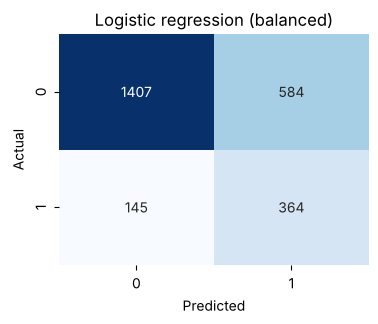

Predicted     0    1
Actual              
0          1407  584
1           145  364

Accuracy = 0.7084
              precision    recall  f1-score   support

      Stayed       0.91      0.71      0.79      1991
        Left       0.38      0.72      0.50       509

    accuracy                           0.71      2500
   macro avg       0.65      0.71      0.65      2500
weighted avg       0.80      0.71      0.73      2500



In [ ]:
logistic_balanced = LogisticRegression(max_iter=1000, class_weight="balanced")
logistic_balanced.fit(X_train_scaled, y_train)
y_pred_lrb = logistic_balanced.predict(X_test_scaled)

evaluate("Logistic regression (balanced)", y_test, y_pred_lrb)

The result changes completely. The model now finds 364 of the 509 leavers (recall of 0.72 instead of 0.21). The price to pay is a large number of false alarms. The model flags 948 customers and only 364 of them really leave (precision of 0.38). The accuracy falls to 70.84%, below the naive model.

This is the trade-off between precision and recall. Which model is better depends on the costs for the bank. If contacting a customer is cheap and losing one is expensive, it is better to accept false alarms and to miss fewer leavers.

### 8.4 Model 3. Random forest

A random forest builds many decision trees and lets them vote. It can find relations that are not straight lines, like the one we saw for the number of products. Trees do not need standardised variables, so we use the original data.

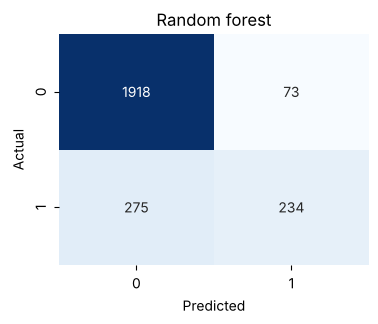

Predicted     0    1
Actual              
0          1918   73
1           275  234

Accuracy = 0.8608
              precision    recall  f1-score   support

      Stayed       0.87      0.96      0.92      1991
        Left       0.76      0.46      0.57       509

    accuracy                           0.86      2500
   macro avg       0.82      0.71      0.75      2500
weighted avg       0.85      0.86      0.85      2500



In [ ]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=0)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

evaluate("Random forest", y_test, y_pred_rf)

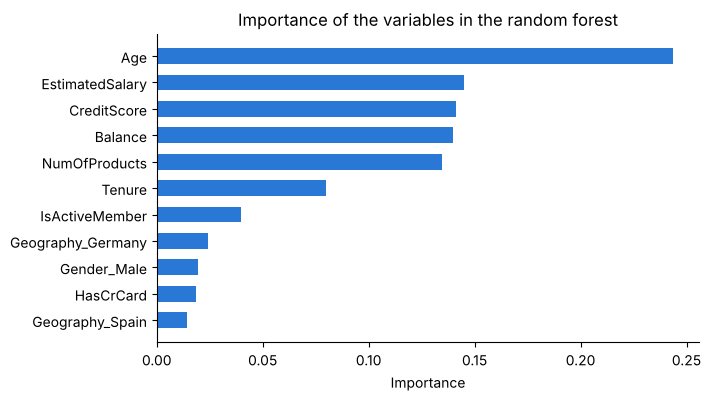

Age                  0.244
EstimatedSalary      0.145
CreditScore          0.141
Balance              0.140
NumOfProducts        0.135
Tenure               0.080
IsActiveMember       0.040
Geography_Germany    0.024
Gender_Male          0.019
HasCrCard            0.019
Geography_Spain      0.014
dtype: float64


In [ ]:
# Importance of each variable in the random forest
feature_importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 4))
plt.barh(feature_importance.index, feature_importance.values, color=COLOR_STAYED, height=0.6)
plt.title("Importance of the variables in the random forest")
plt.xlabel("Importance")
plt.show()

print(feature_importance.sort_values(ascending=False).round(3))

**Performance** The random forest has the best accuracy of the three models (86.08%, more than 6 points above the naive model). It finds 234 of the 509 leavers (recall of 0.46). When it flags a customer it is right 76% of the time (234 out of 307).

**Importance of the variables** Age is by far the most important variable (0.244), which confirms everything we saw before. The number of products is much more important here (0.135) than in the logistic regression, because trees can deal with a relation that goes down and then up.

We have to be careful with one result. The estimated salary is ranked second (0.145), but the Mann-Whitney test showed no difference in salary between leavers and stayers. This type of importance tends to favour continuous variables with many different values, because they offer more possible cut points to the trees. We therefore do not conclude that salary influences churn, and for salary and credit score we trust the tests of section 7 more than this ranking.

### 8.5 Comparison of the models

In [ ]:
# Scores of the three models on the same 2,500 test customers
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(3)

,Accuracy,Precision (Left),Recall (Left),F1 (Left)
Model,,,,
Logistic regression,0.809,0.584,0.212,0.311
Logistic regression (balanced),0.708,0.384,0.715,0.500
Random forest,0.861,0.762,0.460,0.574


- The random forest has the best accuracy (0.861), the best precision (0.762) and the best F1-score (0.574). It is the best general model.
- The balanced logistic regression has the best recall (0.715). It misses the fewest leavers, but with many false alarms.
- The simple logistic regression is the weakest. Its accuracy (0.809) hides a recall of only 0.212.

We would recommend the random forest if the bank wants a reliable list of customers at risk, and the balanced logistic regression if the priority is to miss as few leavers as possible. In both cases the model does not replace the judgement of an advisor. It helps to decide which customers to contact first.

### 8.6 Using the model on new customers

To show how the bank could use the model, we invent two customers and ask the random forest for their probability of leaving.

- Customer A is a 52 year old German woman, not active, with one product and 120,000 on her account.
- Customer B is a 30 year old French man, active, with two products and an empty account.

In [ ]:
new_customers = pd.DataFrame({
    "CreditScore": [650, 650],
    "Age": [52, 30],
    "Tenure": [5, 5],
    "Balance": [120000, 0],
    "NumOfProducts": [1, 2],
    "HasCrCard": [1, 1],
    "IsActiveMember": [0, 1],
    "EstimatedSalary": [100000, 100000],
    "Geography_Germany": [1, 0],
    "Geography_Spain": [0, 0],
    "Gender_Male": [0, 1],
}, index=["Customer A", "Customer B"])

new_customers = new_customers[X.columns]   # same column order as the training data
probability = rf_model.predict_proba(new_customers)[:, 1]

print("Probability of leaving for customer A =", round(probability[0], 2))
print("Probability of leaving for customer B =", round(probability[1], 2))

Probability of leaving for customer A = 0.62
Probability of leaving for customer B = 0.0


The forest gives customer A a probability of leaving of 0.62 and customer B a probability of 0. Customer A has all the characteristics that we found risky (older, German, inactive, a single product) and customer B has none of them. The bank could use these probabilities to rank its customers and contact first those with the highest risk.

## 9. Conclusions

**Who are the customers who leave?**

One customer in five left the bank (20.37%, with a 95% confidence interval from 19.58% to 21.16%). Compared with a stayer, the typical leaver is older (median age of 45 against 36), more often a woman, more often German, less active, and holds either a single product or more than two.

**Are these differences real?**

Yes for most of them. At the 5% level the tests confirm that age, balance, country, gender, activity and number of products are linked to churn. Tenure, salary and credit card are not. The credit score is statistically significant, but the difference is too small to be useful.

**Can we predict churn?**

Partly. Our best model, the random forest, is right for 86% of the test customers and finds 46% of the leavers. A balanced logistic regression finds 72% of them but with many false alarms. Age is the main predictor in every model.

**What we would recommend to the bank**

1. Target the customers older than 50 first. 44.65% of them left, against 20.37% for the whole bank.
2. Investigate Germany. The churn rate there (32.4%) is twice the rate of France and Spain, and German customers hold the highest balances, so each departure costs more deposits.
3. Reactivate inactive members. They leave almost twice as often as active members (26.9% against 14.3%).
4. Look closely at the 326 customers with 3 or 4 products, because 280 of them left (86%). It could mean that these customers were sold products they did not need, but our data cannot confirm it.
5. Do not build the retention plan on credit cards, salary or seniority. They are not linked to churn in our data.

**Limits of our work**

- The dataset is a snapshot. We do not know when each customer left, so we could not study churn over time.
- Our results show associations, not causes. We know that German customers leave more, but not why.
- The bank is anonymous and Kaggle gives little information on how the data were collected, so the results should be read as a case study.
- We used the models with their default settings and a decision threshold of 50%. Tuning the models or changing the threshold could improve the recall.